In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os, sys

from matplotlib import colormaps
import matplotlib.colors as mcolors
import matplotlib.cm as cm

In [2]:
def density_jump(mach, gamma=5/3):
    '''Density jump at a shock as a function of Mach number and adiabatic index gamma'''
    return (gamma + 1) * mach**2 / ( (gamma - 1) * mach**2 + 2)

def pressure_jump(mach, gamma=5/3):
    '''Pressure jump at a shock as a function of Mach number and adiabatic index gamma'''
    return 2 * gamma * mach**2 / (gamma + 1) - (gamma - 1) / (gamma + 1)

def therm_eff(mach, gamma=5/3):
    '''Thermal leakage injection efficiency as in Kang & Jones 2007'''
    return 2 * (pressure_jump(mach, gamma) - density_jump(mach, gamma)**gamma) / (gamma * (gamma - 1) * mach**2 * density_jump(mach, gamma))

def craccel_mach_nocrs(mach, params ):
    '''As in Kang & Jones 2007'''
    if mach <= 2:
        return 1.96e-3 * (mach**2 - 1)
    else:
        return np.sum(params * np.array( [(mach - 1)**n for n in range(0,5)] ) / mach**4)

def craccel_mach_withcrs(mach, params ):
    '''As in Kang & Jones 2007'''
    if mach <= 1.5:
        return 1.025 * therm_eff(mach)
    else:
        return np.sum(params * np.array( [(mach - 1)**n for n in range(0,5)] ) / mach**4)
    
def craccel_mgob(theta_B, theta_crit=np.pi/4, delta_B=np.pi/18):
    '''As in Pais et al 2018'''
    return 0.5 * (np.tanh( (theta_crit - theta_B) / delta_B) + 1)


def craccel_machs_nocrs(machs, params= np.array([5.46, -9.78, 4.17, -0.334, 0.57])):
    return np.array([craccel_mach_nocrs(m, params) for m in machs])

def craccel_machs_withcrs(machs, params= np.array([0.240, -1.56, 2.80, 0.512, 0.557])):
    return np.array([craccel_mach_withcrs(m, params) for m in machs])

Plot for dependence of mach number only

In [3]:
# dependence of mach number only
mach_arr = np.logspace(0, 3, 1000)
craccel_mach_arr = craccel_machs_nocrs(mach_arr)
craccel_mach_crs_arr = craccel_machs_withcrs(mach_arr)

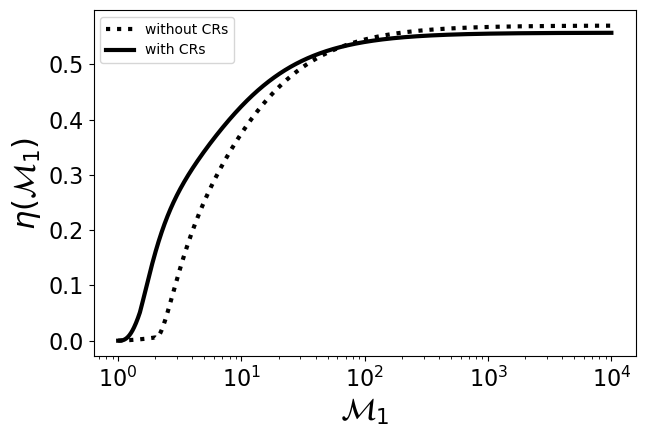

In [13]:
fig, ax = plt.subplots(figsize=(7,4.5))

ax.plot(mach_arr, craccel_mach_arr, ls=":", color="k", lw=3.0, label="without CRs")
ax.plot(mach_arr, craccel_mach_crs_arr, ls="-", color="k", lw=3.0, label="with CRs")

ax.set_xlabel(r"$\mathcal{M}_1$", fontsize=22)

ax.set_ylabel(r"$\eta(\mathcal{M}_1)$", fontsize=22)

ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=14)

ax.legend()

ax.set_xscale("log")

# fig.savefig(os.path.join("/home/watanabe/Projects/meerkat_bowshocks/figures/sod_crinj", "cracceleff_mach.pdf"), dpi=300, bbox_inches="tight")

plot just as function of magnetic obliquity

In [14]:
thetaB_arr = np.linspace(0, 90, 1000)
craccel_mgob_arr = craccel_mgob(np.deg2rad(thetaB_arr))

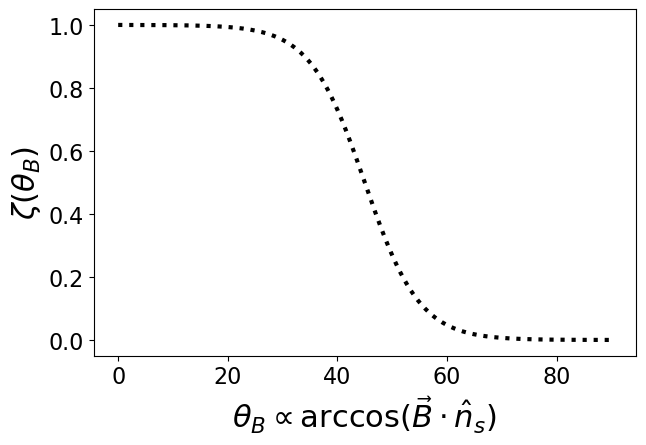

In [15]:
fig, ax = plt.subplots(figsize=(7,4.5))

ax.plot(thetaB_arr, craccel_mgob_arr, ls=":", color="k", lw=3.0)

ax.set_xlabel(r"$\theta_B \propto \arccos(\vec{B} \cdot \hat{n}_s)$", fontsize=22)

ax.set_ylabel(r"$\zeta(\theta_B)$", fontsize=22)

ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=14)

# ax.set_xscale("log")

# fig.savefig(os.path.join("/home/watanabe/Projects/meerkat_bowshocks/figures/sod_crinj", "cracceleff_mach.pdf"), dpi=300, bbox_inches="tight")

plot with different magnetic obliquity values

In [4]:
# dependence with theta_B, fixed values of mach
mach_arr = np.logspace(0, 3, 1000)
thetaB_list = [15, 30, 45, 60]

craccel_arr = np.zeros((len(thetaB_list), len(mach_arr)))
craccel_crs_arr = np.zeros((len(thetaB_list), len(mach_arr)))
for i, thetaB in enumerate(thetaB_list):
    craccel_arr[i,:] = craccel_mgob(np.deg2rad(thetaB)) * craccel_mach_arr
    craccel_crs_arr[i,:] = craccel_mgob(np.deg2rad(thetaB)) * craccel_mach_crs_arr

craccel_rescale = 0.333 # 0.2 / 0.6

In [5]:
# create color based on normalization
norm = mcolors.Normalize(vmin=0, vmax=max(thetaB_list))
cmap = colormaps["copper"]

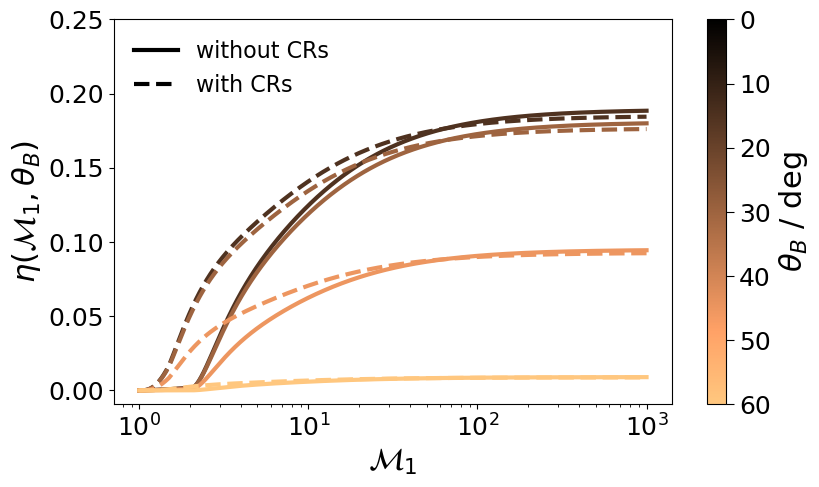

In [7]:
fig, ax = plt.subplots(figsize=(9,5))

for i, thetaB in enumerate(thetaB_list):
    ax.plot(mach_arr, craccel_rescale * craccel_arr[i,:] , ls="-", color=cmap(norm(thetaB)), lw=3.0, label=fr"$\theta_B$ = {thetaB:.0f}$^\circ$")
    ax.plot(mach_arr, craccel_rescale * craccel_crs_arr[i,:] , ls="--", color=cmap(norm(thetaB)), lw=3.0, label=None)

ax.set_xlabel(r"$\mathcal{M}_1$", fontsize=22)
ax.set_ylabel(r"$\eta(\mathcal{M}_1, \theta_B)$", fontsize=22)

ax.tick_params(axis='both', which='major', labelsize=18)
ax.tick_params(axis='both', which='minor', labelsize=16)

ax.set_xscale("log")
# ax.set_yscale("log")
ax.legend(
    handles=[
        plt.Line2D([0], [0], color="k", lw=3.0, ls="-", label="without CRs"),
        plt.Line2D([0], [0], color="k", lw=3.0, ls="--", label="with CRs"),
    ],
    fontsize=16,
    loc="upper left",
    frameon=False,
    framealpha=0.0
)

ax.set_ylim(ymax=0.25)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax)
cbar.ax.set_ylabel(r"$\theta_B$ / deg", fontsize=22)
cbar.ax.invert_yaxis()
cbar.ax.tick_params(axis='both', which='major', size=6, labelsize=18)
cbar.ax.tick_params(axis='both', which='minor', size=4, labelsize=18)

fig.savefig(os.path.join("/home/kwatanabe/Projects/cr-bowshocks/figures/sod_tests", "cracceleff.pdf"), dpi=300, bbox_inches="tight")